<div align="center">

#### **PEMBUATAN RECIPE**

#### **_Synthetic Rainfall–Runoff Reference Implementation_**


#### **KECERDASAN ARTIFISIAL GEOFISIKA**



#### **NABILA KIRANA AINUN**

#### **H061241030**

#### **DEPARTEMEN GEOFISIKA**

#### **FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM**

#### **UNIVERSITAS HASANUDDIN**

![Screenshot 2026-10-21 093849.png](<attachment:Screenshot 2026-10-21 093849.png>)
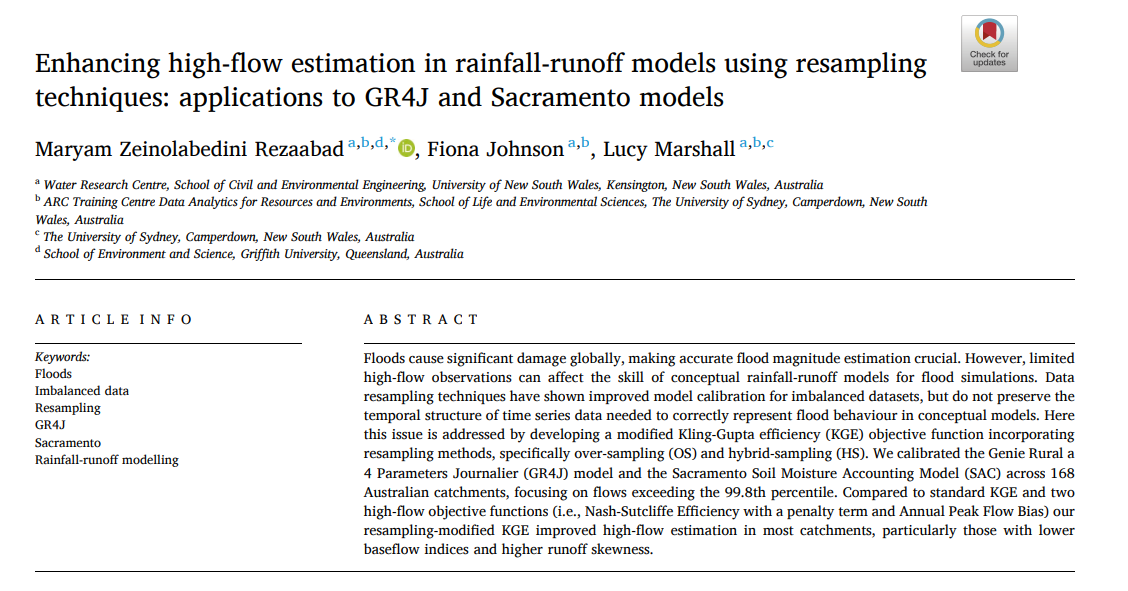

R-CS-002 adalah reference implementation model hujan–aliran (rainfall–runoff) yang sepenuhnya sintetis. Recipe ini tidak dimaksudkan untuk memprediksi banjir atau menggambarkan catchment nyata. Fungsinya sebagai uji kontrak (contract check): sebelum model reservoir linear dipakai pada data catchment sungguhan, kita memastikan dulu bahwa implementasinya benar. Caranya, kita membangun hydrograph “referensi” dari parameter yang sudah diketahui, lalu memeriksa apakah prosedur pencarian parameter dapat menemukan kembali parameter tersebut. Karena itu bagian Problem menyebut “memeriksa contract reservoir linear sebelum memakai data catchment”. Prasyaratnya ringan: komputasi lokal dengan Python, tanpa dependensi AI, dan bukti status tetap mengikuti teks.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_880\1824390979.py:39: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(data.round(3).to_string(index=False))


   Tanggal  Curah Hujan (mm/hari)  Debit Model (satuan relatif)
2026-01-01                    0.0                         0.000
2026-01-02                   15.0                         0.511
2026-01-03                   22.0                         1.012
2026-01-04                    3.0                         0.622
2026-01-05                    0.0                         0.319
2026-01-06                    7.0                         0.402
2026-01-07                   35.0                         1.399
2026-01-08                    4.0                         0.854
2026-01-09                    0.0                         0.439
2026-01-10                    0.0                         0.225
2026-01-11                   12.0                         0.524
2026-01-12                    2.0                         0.337


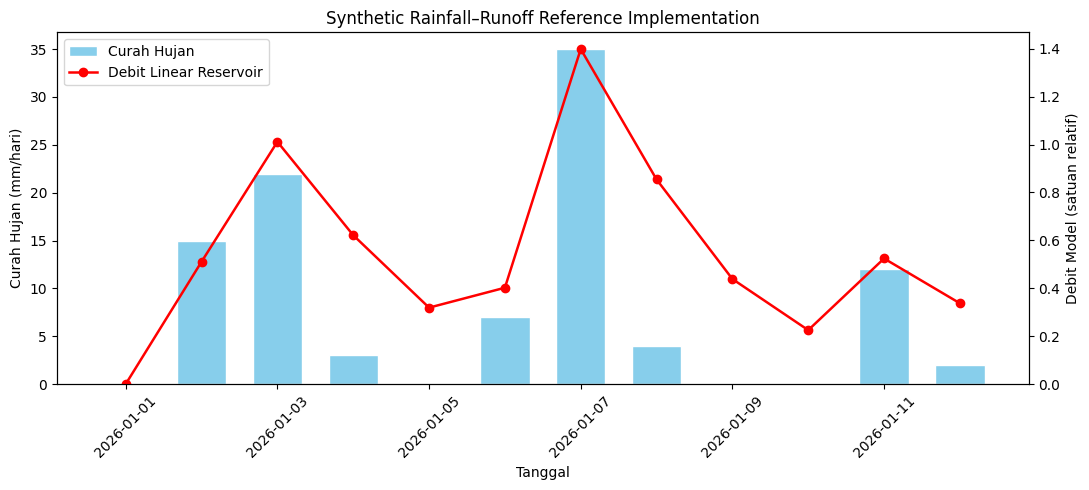

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Membuat data curah hujan sintetis
tanggal = pd.date_range(
    start="2026-01-01",
    periods=12,
    freq="D"
)

rainfall = np.array([
    0, 15, 22, 3, 0, 7,
    35, 4, 0, 0, 12, 2
], dtype=float)

# 2. Menentukan parameter linear reservoir
K = 1.5       # Konstanta waktu reservoir (hari)
alpha = 0.07  # Faktor konversi masukan hujan ke debit

# 3. Menghitung debit hasil pemodelan
discharge = np.zeros(len(rainfall))

for i in range(1, len(rainfall)):
    decay = np.exp(-1 / K)

    discharge[i] = (
        decay * discharge[i - 1]
        + alpha * (1 - decay) * rainfall[i]
    )

# 4. Menyimpan hasil ke dalam DataFrame
data = pd.DataFrame({
    "Tanggal": tanggal,
    "Curah Hujan (mm/hari)": rainfall,
    "Debit Model (satuan relatif)": discharge
})

print(data.round(3).to_string(index=False))

# 5. Membuat grafik curah hujan dan debit
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.bar(
    tanggal,
    rainfall,
    width=0.65,
    color="skyblue",
    edgecolor="white",
    label="Curah Hujan"
)

ax1.set_xlabel("Tanggal")
ax1.set_ylabel("Curah Hujan (mm/hari)")
ax1.set_ylim(bottom=0)
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()

ax2.plot(
    tanggal,
    discharge,
    color="red",
    marker="o",
    linewidth=1.8,
    label="Debit Linear Reservoir"
)

ax2.set_ylabel("Debit Model (satuan relatif)")
ax2.set_ylim(bottom=0)

# Menggabungkan legenda kedua sumbu
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="upper left"
)

plt.title("Synthetic Rainfall–Runoff Reference Implementation")
plt.tight_layout()
plt.show()

**Analisis Hasil**

Berdasarkan grafik yang dihasilkan, curah hujan sintetis menunjukkan pola yang berubah-ubah selama periode pengamatan. Terdapat beberapa kejadian hujan dengan intensitas yang relatif tinggi, terutama pada hari dengan curah hujan sebesar 22 mm/hari dan 35 mm/hari. Perubahan tersebut menjadi masukan bagi model linear reservoir untuk menghitung perubahan debit aliran. Ketika curah hujan meningkat, debit hasil pemodelan cenderung meningkat karena bertambahnya masukan air ke dalam sistem penyimpanan. Sebaliknya, ketika curah hujan berkurang atau tidak terjadi hujan, debit cenderung menurun secara bertahap akibat pelepasan air yang masih tersimpan di dalam reservoir.

Hasil pemodelan juga memperlihatkan pentingnya parameter konstanta waktu reservoir (\(K\)) dalam menentukan respons hidrologi. Pada kode yang digunakan, nilai \(K=1{,}5\) hari mengontrol seberapa cepat pengaruh masukan hujan berkurang dari waktu ke waktu. Air yang tersimpan tidak langsung hilang ketika hujan berhenti, tetapi dilepaskan secara bertahap sehingga debit dapat tetap bernilai positif setelah kejadian hujan. Karakteristik tersebut merupakan salah satu keunggulan metode linear reservoir karena mampu merepresentasikan efek penyimpanan air secara sederhana. Namun, keterlambatan puncak debit pada model ini tidak selalu sama dengan kondisi sungai sebenarnya, karena sangat bergantung pada parameter model, pola masukan hujan, dan proses hidrologi yang tidak dimasukkan dalam perhitungan.

Dari sisi interpretasi, grafik curah hujan dan debit memberikan gambaran mengenai hubungan antara masukan air dan respons aliran. Curah hujan merupakan faktor pemicu, sedangkan debit merupakan respons sistem terhadap masukan tersebut. Meskipun demikian, nilai debit yang dihasilkan dalam kode ini masih berupa satuan relatif karena faktor konversi yang digunakan belum dikalibrasi berdasarkan luas DAS, karakteristik infiltrasi, dan pengukuran debit aktual. Oleh sebab itu, hasilnya belum dapat digunakan untuk menentukan debit banjir rencana atau menilai risiko banjir secara kuantitatif. Untuk aplikasi nyata, model perlu dikembangkan menggunakan data curah hujan dan debit observasi, serta diuji melalui parameter evaluasi seperti Root Mean Square Error (RMSE), Nash–Sutcliffe Efficiency (NSE), atau koefisien determinasi (\(R^2\)).